# Triangle geometry and interpolation error

This executable experiment uses the OneSimulation dense linear solver. Change the parameters passed to `experiment` in the final cell. The plotted height is a scalar field; it is not a third spatial coordinate. Outputs below were generated by running this code.

In [1]:
"""Inspect shape-dependent interpolation error with a OneSimulation dense solve."""
import argparse
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense


def experiment(base=0.5, ratio=0.25):
    if base <= 0 or ratio <= 0:
        raise ValueError("Base and altitude/base ratio must be positive")
    altitude = base * ratio
    vertices = np.array([[0., 0.], [base, 0.], [base/2, altitude]])
    # The affine interpolation coefficients reproduce the three nodal values.
    vandermonde = np.column_stack((np.ones(3), vertices))
    coefficients = solve_dense(vandermonde, vertices[:, 0]**2)
    expected = np.array([0., base, -base**2/(4*altitude)])
    np.testing.assert_allclose(coefficients, expected, atol=2e-14)
    gradient_error = np.sqrt(base*altitude/2 * (base**2/6 + base**4/(16*altitude**2)))
    print(f"Affine coefficients: {coefficients}")
    print(f"L2 norm of gradient error: {gradient_error:.8f}")

    barycentric = np.array([(i/30, j/30) for i in range(31) for j in range(31-i)])
    points = np.column_stack((base*(barycentric[:, 0]+barycentric[:, 1]/2), altitude*barycentric[:, 1]))
    exact = points[:, 0]**2
    linear = coefficients[0] + points @ coefficients[1:]
    fig = plt.figure(figsize=(10, 4.4), layout="constrained")
    ax = fig.add_subplot(121, projection="3d")
    ax.plot_trisurf(points[:, 0], points[:, 1], exact, color="#a6c8be", alpha=.8)
    for fraction in np.linspace(0, 1, 9):
        y = altitude*fraction
        x = np.linspace(base*fraction/2, base*(1-fraction/2), 40)
        ax.plot(x, np.full_like(x, y), coefficients[0]+coefficients[1]*x+coefficients[2]*y,
                color="#ad491d", lw=1)
    ax.set(xlabel="x", ylabel="y", zlabel="Scalar field u", title="Exact surface and affine interpolant")
    error = fig.add_subplot(122)
    ratios = np.geomspace(.02, 1, 100)
    error.loglog(ratios, base/(4*ratios), label="Spurious transverse gradient")
    error.scatter(ratio, abs(coefficients[2]), color="#ad491d")
    error.set(xlabel="Altitude / base", ylabel="Magnitude of transverse gradient")
    error.legend()
    fig.savefig("complete-numerics-triangle.png", dpi=170)
    return coefficients, gradient_error




Affine coefficients: [ 0.   0.5 -0.5]
L2 norm of gradient error: 0.09547033


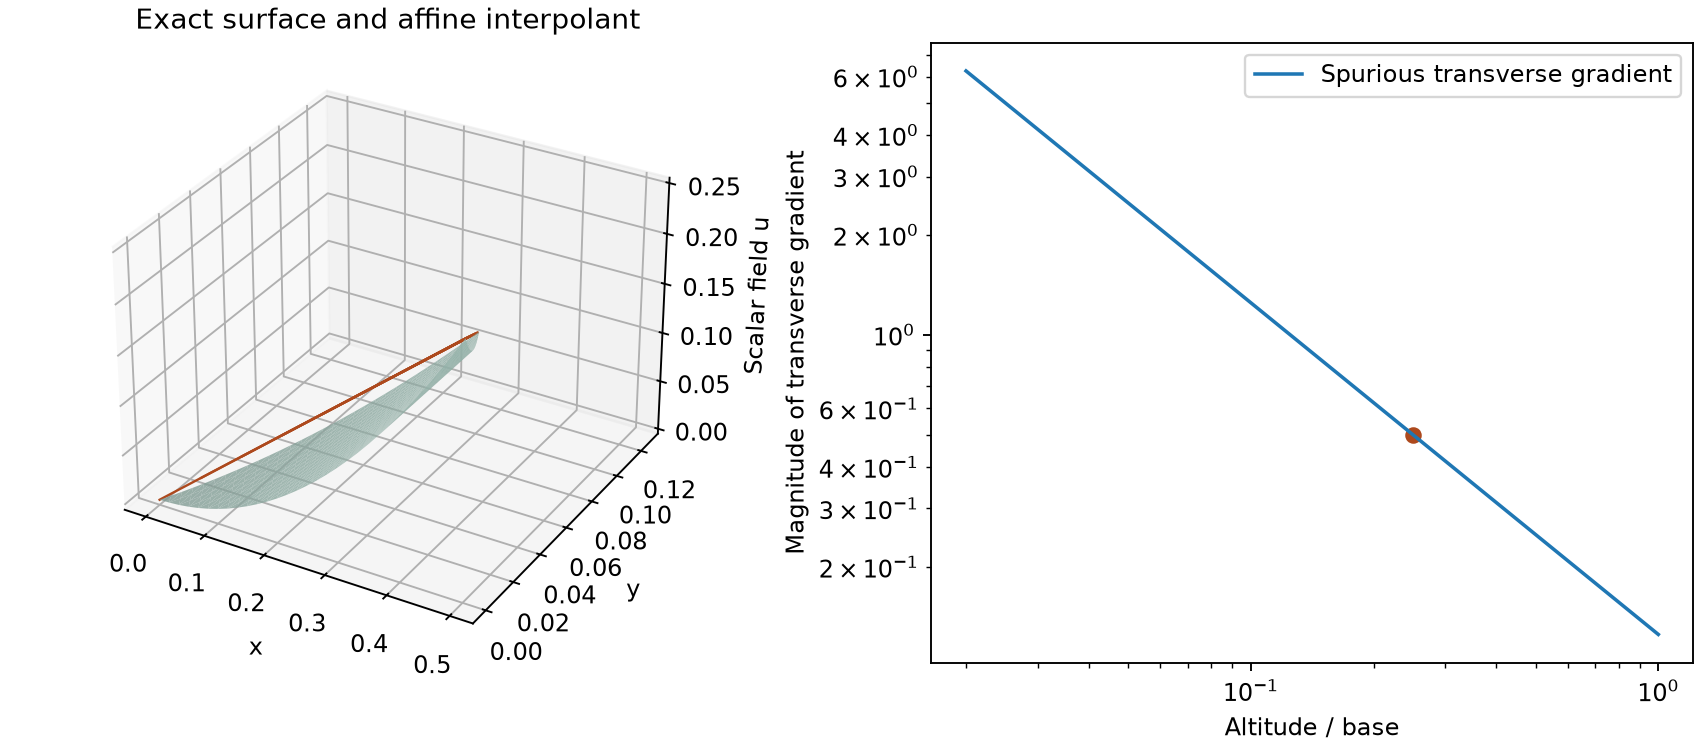

In [2]:
experiment(base=0.5, ratio=0.25)
plt.show()